# ТК 5-6 (ПР3): kNN — качество красного вина
Метод k ближайших соседей (kNN) - это алгоритм классификации, относящий объект к тому классу, который чаще встречается среди его k ближайших соседей в пространстве признаков.

Датасет - это таблица с данными, на которой обучается и проверяется модель. Сплит (train/test, обучающая и тестовая выборки) - это разделение датасета на обучающую часть, по которой настраивается модель, и тестовую, на которой независимо оценивается её качество. Стратификацией называют способ разбиения, при котором доли классов сохраняются в каждой из частей.

В данной работе задача сведена к бинарной классификации: качество вина разделено на два класса, подробности см. в разделе «Бинаризация».

In [1]:
# Импорты и настройки
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import itertools

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, roc_curve, roc_auc_score

%matplotlib inline
plt.rcParams["figure.figsize"] = (10,5)

## Загрузка

In [2]:
# Читаем CSV
df = pd.read_csv('docs/winequality-red.csv')

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Описание данных

In [3]:
# Типы столбцов и пропуски
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


## Бинаризация
Бинарная классификация - это задача классификации, в которой объект относится к одному из двух возможных классов.

В датасете о качестве вина исходный признак `quality` принимает значения от 3 до 8. Чтобы свести задачу к бинарной, введём порог: оценки 5 и ниже считаем плохим вином (класс 0), а оценки 6 и выше — хорошим (класс 1). Порог 6 выбран как «не ниже среднего»: он даёт почти сбалансированное разбиение — 855 образцов хорошего и 744 плохого вина.

In [4]:
# Бинарный целевой признак: 1 — хорошее вино (quality >= 6), 0 — плохое
df['good'] = (df['quality'] >= 6).astype(int)
print(df['good'].value_counts().sort_index())

good
0    744
1    855
Name: count, dtype: int64


## Баланс классов
Баланс классов - это соотношение числа объектов разных классов в выборке; данные, где классы представлены сильно неравномерно, называют несбалансированными, и это сказывается на метриках качества.

На графике ниже показано распределение бинарного признака `good`: по оси x отложены классы 0 (плохое вино) и 1 (хорошее), по оси y — число образцов каждого класса. Столбцы близки по высоте, поэтому классы почти сбалансированы, а macro- и weighted-метрики качества будут близки друг к другу.

missing cells: 0
full-row duplicates: 240
good
0    744
1    855
Name: count, dtype: int64


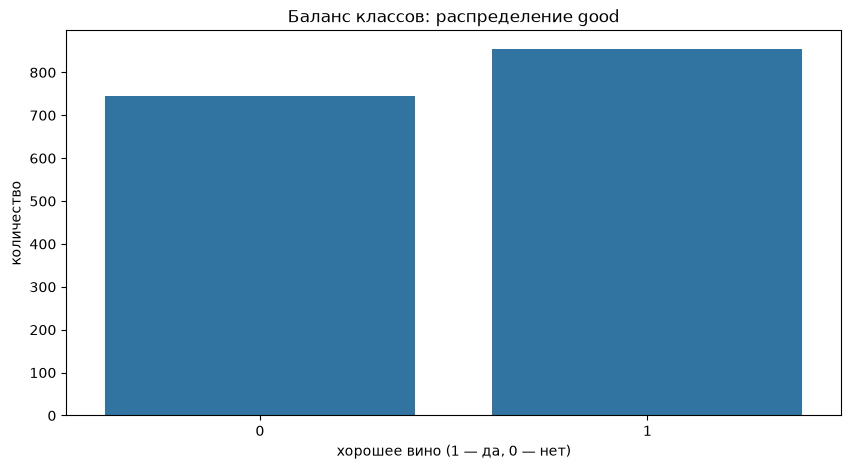

In [5]:
# Распределение бинарного признака good
sns.countplot(x='good', data=df)
plt.xlabel('хорошее вино (1 — да, 0 — нет)')
plt.ylabel('количество')
plt.title('Баланс классов: распределение good')

# Проверяем пропуски и дубликаты
print('missing cells:', int(df.isna().sum().sum()))
print('full-row duplicates:', int(df.duplicated().sum()))
print(df['good'].value_counts().sort_index())

## Функция отрисовки матрицы путаницы
Матрица путаницы - это таблица, в которой строки соответствуют фактическим классам, столбцы — предсказанным, а ячейки содержат число объектов с таким сочетанием.

In [6]:
# Отрисовка матрицы путаницы
def display_confusion_matrix(
    matrix, labels=None,
    title="Матрица путаницы (k=5, тестовая выборка)",
    xlabel="Предсказано",
    ylabel="Фактически",
    figsize=None,
    cmap="Blues",
    vmin=None,
    vmax=None,
):
    if labels is None:
        labels = [""]*len(matrix)
    if vmin is None:
        vmin = 0.
    if vmax is None:
        vmax = np.sum(matrix[0])
    t_hold = (vmax-vmin) / 2.
    fig,ax = plt.subplots(figsize=figsize)
    ax.imshow(matrix, cmap=cmap)
    for row,col in itertools.product(range(len(labels)), range(len(labels))):
        color = "white" if matrix[row,col] > t_hold else "black"
        ax.text(col, row, matrix[row, col], horizontalalignment="center", color=color)
    tick_marks = np.arange(len(labels))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=40, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_yticks(np.arange(len(labels)))
    ax.set_yticklabels(labels)
    plt.show()

## Сплит train/test
Стратификация сохраняет доли классов в обеих выборках.

In [7]:
# Стратифицированный сплит; random_state=42 — для воспроизводимости
X = df.drop(['quality', 'good'], axis=1)
y = df['good']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)

## Обучение
Baseline (базовая модель) - это простая исходная модель, служащая точкой сравнения для более сложных решений.

k=5 по умолчанию, без масштабирования — baseline.

In [8]:
# kNN, k=5 по умолчанию
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## Метрики
Precision (точность) - это доля объектов, отнесённых моделью к классу, которые действительно к нему принадлежат.
Recall (полнота) - это доля объектов класса, которые модель правильно распознала.
F1-мера - это среднее гармоническое точности и полноты, объединяющее обе метрики в одно число.
Accuracy (доля правильных ответов) - это доля всех объектов, для которых модель дала верный прогноз.

Отчёт выводит precision/recall/F1 по классам и общую accuracy.

In [9]:
# Метрики на тесте
preds = knn.predict(X_test)

print(classification_report(y_test, preds))
print('accuracy:', accuracy_score(y_test, preds))

              precision    recall  f1-score   support

           0       0.60      0.66      0.63       223
           1       0.68      0.62      0.65       257

    accuracy                           0.64       480
   macro avg       0.64      0.64      0.64       480
weighted avg       0.64      0.64      0.64       480

accuracy: 0.6395833333333333


## Матрица путаницы
Строки матрицы соответствуют фактическим классам (0 — плохое вино, 1 — хорошее), столбцы — прогнозам модели; цвет ячейки и число в ней показывают, сколько образцов получили данную пару «фактический–предсказанный» класс. По диагонали отслеживаются правильные ответы, а внедиагональные ячейки показывают ложные срабатывания (плохое вино предсказано как хорошее) и пропуски (хорошее вино предсказано как плохое).

[[147  76]
 [ 97 160]]


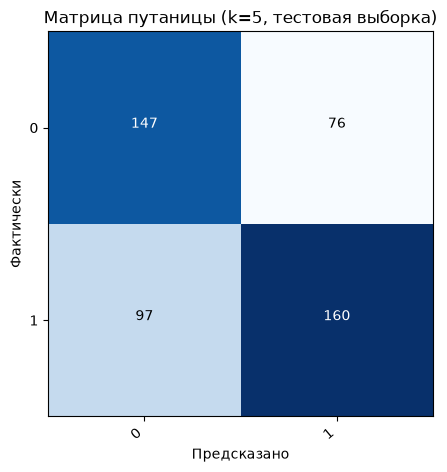

In [10]:
# Матрица путаницы
labels = y.unique()

matrix = confusion_matrix(y_test, preds, labels=labels, normalize=None)
print(matrix)

display_confusion_matrix(matrix, labels)

## Зависимость от k
Переобучение - это ситуация, когда модель слишком точно запоминает обучающую выборку и теряет способность обобщать на новых данных.

На графике ниже по оси x отложено число соседей k, а по оси y — значения точности на обучающей и тестовой выборках и macro-recall. Разрыв между кривыми train и test позволяет оценить степень переобучения: чем ближе кривые и выше значения на тесте, тем лучше модель обобщается.

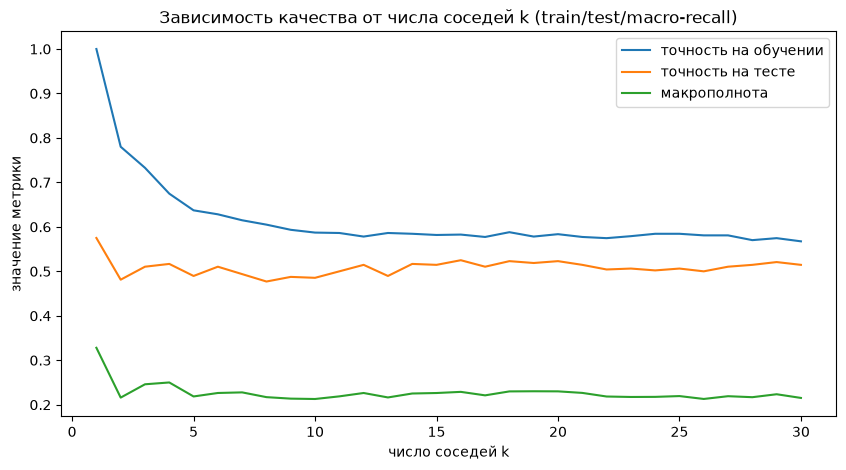

In [11]:
# Точность train/test при k=1..30
from wine_knn import k_sweep
rows = k_sweep('docs/winequality-red.csv')
k_values = [row['k'] for row in rows]
train_accuracy = [row['train_accuracy'] for row in rows]
test_accuracy = [row['test_accuracy'] for row in rows]
recall_macro = [row['recall_macro'] for row in rows]
plt.plot(k_values, train_accuracy, label='точность на обучении')
plt.plot(k_values, test_accuracy, label='точность на тесте')
plt.plot(k_values, recall_macro, label='макрополнота')
plt.xlabel('число соседей k'); plt.ylabel('значение метрики'); plt.legend(); plt.title('Зависимость качества от числа соседей k (train/test/macro-recall)'); plt.show()

## ROC-кривая
Доля истинноположительных (TPR) - это доля объектов положительного класса, которых модель правильно распознала.
Доля ложноположительных (FPR) - это доля объектов отрицательного класса, которых модель ошибочно отнесла к положительному.
ROC-кривая - это график зависимости доли истинноположительных ответов (TPR) от доли ложноположительных (FPR) при изменении порога классификации.
AUC - это площадь под ROC-кривой, количественная мера способности модели различать классы.

На графике по оси x отложена доля ложноположительных ответов (FPR), по оси y — доля истинноположительных (TPR). Пунктирная диагональ соответствует случайному классификатору, а величина AUC в легенде показывает, насколько хорошо бинарная модель отделяет хорошее вино от плохого.

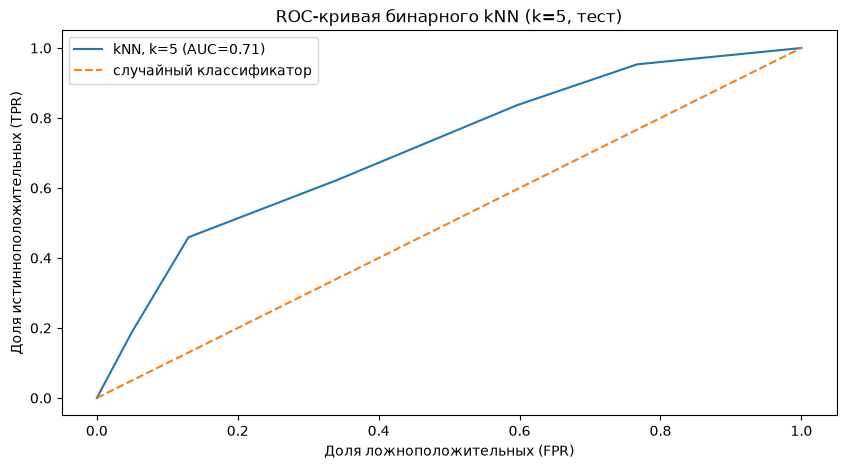

In [12]:
# ROC бинарного kNN; AUC - площадь под ROC-кривой
proba_good = knn.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba_good)
auc = roc_auc_score(y_test, proba_good)
plt.plot(fpr, tpr, label=f'kNN, k=5 (AUC={auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='случайный классификатор')
plt.xlabel('Доля ложноположительных (FPR)')
plt.ylabel('Доля истинноположительных (TPR)')
plt.legend()
plt.title('ROC-кривая бинарного kNN (k=5, тест)')
plt.show()

## Выводы
StandardScaler - это преобразование признаков, вычитающее среднее и делящее значения на стандартное отклонение, чтобы привести признаки к единому масштабу.
Pipeline - это последовательность этапов обработки данных и модели, оформленная в scikit-learn как единый объект.

- Переход от многоклассовой задачи к бинарной (качество ≥ 6 — хорошее вино) заметно упрощает постановку: accuracy k=5 на тесте ~0.64 против ~0.49 у шестиклассовой модели; классы почти сбалансированы (223/257 в тесте), поэтому macro- и weighted-метрики совпадают (~0.64).
- Precision/recall/F1 по обоим классам лежат в диапазоне ~0.60–0.68; разрыв accuracy между обучением (~0.76) и тестом указывает на переобучение, которое уменьшается с ростом k.
- Матрица путаницы показывает распределение правильных ответов и ошибок: ложные срабатывания и пропуски хорошего вина встречаются сопоставимо часто.
- ROC-кривая и AUC (~0.71) характеризуют способность модели ранжировать образцы: кривая заметно выше диагонали, но до хорошего разделения классов не дотягивает.
- Диапазоны признаков различаются на порядки; вариант улучшения — StandardScaler в Pipeline.